1. Import Library & Load Dataset

In [36]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.express as px

# Load dataset
file_path = "/content/Canada.xlsx"

df = pd.read_excel(
    file_path,
    sheet_name="Canada by Citizenship",
    skiprows=20,
    skipfooter=2
)

# Menghapus kolom yang tidak diperlukan untuk mempermudah analisis
df = df.drop(columns=["Type", "Coverage", "AREA", "REG", "DEV"])

# Rename kolom agar lebih mudah dipahami
df = df.rename(columns={
    "OdName": "Country",
    "AreaName": "Continent",
    "RegName": "Region",
    "DevName": "Development"
})

# Set Country sebagai index
df = df.set_index("Country")


2. Menampilkan Dataset

In [37]:
df.head()

,Continent,Region,Development,1980,1981,1982,1983,1984,1985,1986,...,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013
Country,,,,,,,,,,,,,,,,,,,,,
Afghanistan,Asia,Southern Asia,Developing regions,16,39,39,47,71,340,496,...,2978,3436,3009,2652,2111,1746,1758,2203,2635,2004
Albania,Europe,Southern Europe,Developed regions,1,0,0,0,0,0,1,...,1450,1223,856,702,560,716,561,539,620,603
Algeria,Africa,Northern Africa,Developing regions,80,67,71,69,63,44,69,...,3616,3626,4807,3623,4005,5393,4752,4325,3774,4331
American Samoa,Oceania,Polynesia,Developing regions,0,1,0,0,0,0,0,...,0,0,1,0,0,0,0,0,0,0
Andorra,Europe,Southern Europe,Developed regions,0,0,0,0,0,0,2,...,0,0,1,1,0,0,0,0,1,1


3. Menampilkan Fitur dan Tipe Dataset

In [38]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 195 entries, Afghanistan to Zimbabwe
Data columns (total 37 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   Continent    195 non-null    object
 1   Region       195 non-null    object
 2   Development  195 non-null    object
 3   1980         195 non-null    int64 
 4   1981         195 non-null    int64 
 5   1982         195 non-null    int64 
 6   1983         195 non-null    int64 
 7   1984         195 non-null    int64 
 8   1985         195 non-null    int64 
 9   1986         195 non-null    int64 
 10  1987         195 non-null    int64 
 11  1988         195 non-null    int64 
 12  1989         195 non-null    int64 
 13  1990         195 non-null    int64 
 14  1991         195 non-null    int64 
 15  1992         195 non-null    int64 
 16  1993         195 non-null    int64 
 17  1994         195 non-null    int64 
 18  1995         195 non-null    int64 
 19  1996         195 no

4. Statistik Deskriptif + Interpretasi

In [39]:
stats = df.describe()
stats

,1980,1981,1982,1983,1984,1985,1986,1987,1988,1989,...,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013
count,195.000000,195.000000,195.000000,195.000000,195.000000,195.000000,195.000000,195.000000,195.000000,195.000000,...,195.000000,195.000000,195.000000,195.000000,195.000000,195.000000,195.000000,195.000000,195.000000,195.000000
mean,508.394872,566.989744,534.723077,387.435897,376.497436,358.861538,441.271795,691.133333,714.389744,843.241026,...,1190.169231,1320.292308,1266.958974,1191.820513,1246.394872,1275.733333,1420.287179,1262.533333,1313.958974,1320.702564
std,1949.588546,2152.643752,1866.997511,1204.333597,1198.246371,1079.309600,1225.576630,2109.205607,2443.606788,2555.048874,...,3710.505369,4425.957828,3926.717747,3443.542409,3694.573544,3829.630424,4462.946328,4030.084313,4247.555161,4237.951988
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.500000,0.500000,1.000000,1.000000,...,19.000000,28.500000,25.000000,31.000000,31.000000,36.000000,40.500000,37.500000,42.500000,45.000000
50%,13.000000,10.000000,11.000000,12.000000,13.000000,17.000000,18.000000,26.000000,34.000000,44.000000,...,191.000000,210.000000,218.000000,198.000000,205.000000,214.000000,211.000000,179.000000,233.000000,213.000000
75%,251.500000,295.500000,275.000000,173.000000,181.000000,197.000000,254.000000,434.000000,409.000000,508.500000,...,756.500000,832.000000,842.000000,899.000000,934.500000,888.000000,932.000000,772.000000,783.000000,796.000000
max,22045.000000,24796.000000,20620.000000,10015.000000,10170.000000,9564.000000,9470.000000,21337.000000,27359.000000,23795.000000,...,36619.000000,42584.000000,33848.000000,28742.000000,30037.000000,29622.000000,38617.000000,36765.000000,34315.000000,34129.000000


5. Visualisasi Tren Perbandingan 5 Negara

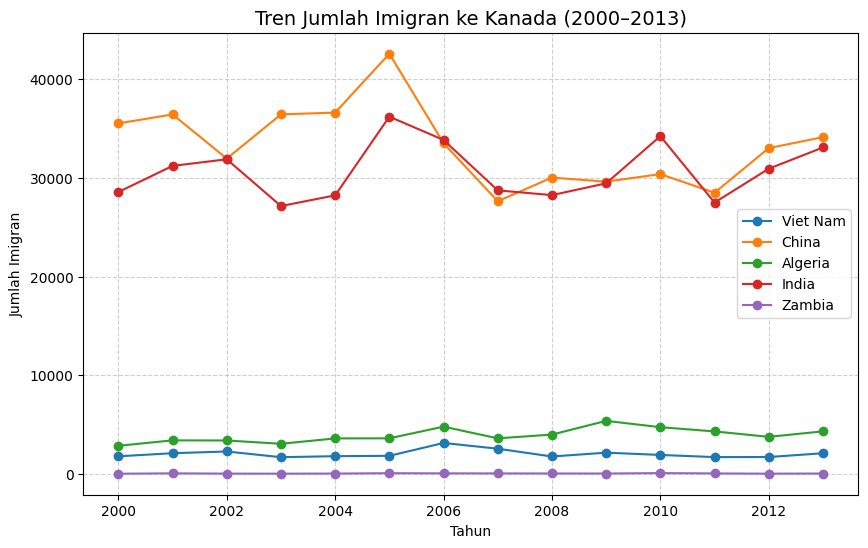

In [40]:
# Memastikan index = nama negara
if "OdName" in df.columns:
    df.set_index("OdName", inplace=True)

# Ambil kolom tahun otomatis (2000–2013), baik string atau integer
years = [col for col in df.columns if str(col).isdigit() and 2000 <= int(col) <= 2013]
years = sorted(years, key=lambda x: int(x))

# Negara yang akan dibandingkan
selected_countries = ["Viet Nam", "China", "Algeria", "India", "Zambia"]

# Ambil data
df_plot = df.loc[selected_countries, years].T
df_plot.index = df_plot.index.astype(int)

# Plot
plt.figure(figsize=(10,6))
for country in df_plot.columns:
    plt.plot(df_plot.index, df_plot[country], marker='o', label=country)

plt.title("Tren Jumlah Imigran ke Kanada (2000–2013)", fontsize=14)
plt.xlabel("Tahun")
plt.ylabel("Jumlah Imigran")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()


6. Visualisasi Jumlah Imigran dari India

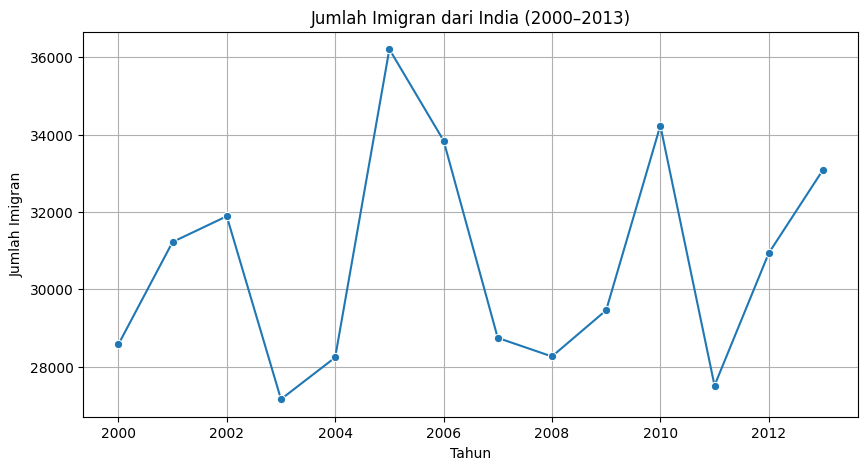

In [41]:
india = df.loc["India", years].T
india.index = india.index.astype(int)

plt.figure(figsize=(10,5))
sns.lineplot(x=india.index, y=india.values, marker='o')
plt.title("Jumlah Imigran dari India (2000–2013)")
plt.xlabel("Tahun")
plt.ylabel("Jumlah Imigran")
plt.grid(True)
plt.show()

7. Visualisasi Geospasial Imigran (Top 10 Negara)

In [42]:
# Hitung total imigran per negara
df_geo = df[years].sum(axis=1).reset_index()
df_geo.columns = ["Country", "Total"]

# Ambil 10 negara dengan total imigran tertinggi
top10 = df_geo.sort_values(by="Total", ascending=False).head(10)

# Peta interaktif
fig = px.scatter_geo(
    top10,
    locations="Country",
    locationmode="country names",
    size="Total",
    color="Total",
    hover_name="Country",
    projection="natural earth",
    title="Asal Imigran Terbesar ke Kanada (2000–2013)"
)
fig.show()
